# TradePulse - Step 7: Baseline Model Benchmarking & Label-Set Comparison
**IIT Patna, IMPACT Lab | End-to-End Machine Learning Guidelines**  
**Asset:** META (NASDAQ) | **Timeframe:** 5-minute | **Horizon:** 15-minute (3 bars ahead)  

---
### Objectives & Rigor Protocol
1. **Purged Walk-Forward CV:** Evaluate all baselines using an expanding-window walk-forward CV (5 folds) with a mandatory 3-bar purge gap to prevent lookahead target overlap.
2. **4 Refined Candidate Label Sets:**
   - `label_fixed_20bp`: Fixed cut $\theta = \pm 0.20\%$
   - `label_quantile_50`: Symmetric median $|R_{\text{train}}| = \pm 0.1472\%$
   - `label_quantile_40`: Symmetric 40th percentile $|R_{\text{train}}| = \pm 0.1134\%$
   - `label_vol_k075`: Causal volatility $\theta_t = \max(0.75 \times \sigma_{t, 3b}, 0.10\%)$
3. **5 Baseline Models:**
   - Majority Class (Always Neutral)
   - Always-Up (+1)
   - Momentum (Sign of $R_{t-1}$)
   - Basic RSI Rule (Oversold < 0.30 -> Up, Overbought > 0.70 -> Down)
   - Logistic Regression (Multinomial with balanced class weights and intra-fold RobustScaler)
4. **Cross-Label Comparisons:** Report both classification metrics (Balanced Acc, Macro-F1) and label-independent economic metrics (cost-adjusted return per trade at 5, 8, 12 bps, and fixed 10% coverage precision).

In [1]:
import sys
import os
import json
from pathlib import Path

# Ensure project root is in sys.path
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ml.train import run_step7_benchmark, BENCHMARK_RESULTS_PATH
from ml.evaluate import PurgedWalkForwardCV

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Libraries and pipeline modules loaded successfully.")

Libraries and pipeline modules loaded successfully.


## 1. Running the Purged Walk-Forward Baseline Benchmark Matrix
We execute 5-fold walk-forward CV across all 5 models and all 4 candidate label sets.

In [2]:
results_df = run_step7_benchmark()
results_df


[TradePulse Step 7: Baseline Benchmark Matrix]
  Valid training bars: 12,193
  Candidate label sets: ['label_fixed_20bp', 'label_quantile_50', 'label_quantile_40', 'label_vol_k075']
  Baselines evaluated: ['Majority (Always Neutral)', 'Always-Up', 'Momentum (Sign R_t-1)', 'Basic RSI (30/70)', 'Logistic Regression']

  Evaluating candidate label set: label_fixed_20bp...
  Evaluating candidate label set: label_quantile_50...
  Evaluating candidate label set: label_quantile_40...
  Evaluating candidate label set: label_vol_k075...

=== Baseline Benchmark Results Summary ===
  Label Candidate                     Model          Macro F1      Balanced Acc Coverage % 8bp Net Ret/Trade 8bp Win Rate 10% Cov Prec
 label_fixed_20bp Majority (Always Neutral) 0.2513 +/- 0.0082 0.3333 +/- 0.0000       0.0%         +0.00 bps         0.0%         0.0%
 label_fixed_20bp                 Always-Up 0.1074 +/- 0.0041 0.3333 +/- 0.0000     100.0%         -7.97 bps        35.3%        33.3%
 label_fixed_20b

,Label Candidate,Model,Macro F1,Balanced Acc,Coverage %,8bp Net Ret/Trade,8bp Win Rate,10% Cov Prec
0,label_fixed_20bp,Majority (Always Neutral),0.2513 +/- 0.0082,0.3333 +/- 0.0000,0.0%,+0.00 bps,0.0%,0.0%
1,label_fixed_20bp,Always-Up,0.1074 +/- 0.0041,0.3333 +/- 0.0000,100.0%,-7.97 bps,35.3%,33.3%
2,label_fixed_20bp,Momentum (Sign R_t-1),0.1856 +/- 0.0110,0.3250 +/- 0.0113,99.6%,-8.43 bps,35.5%,37.7%
3,label_fixed_20bp,Basic RSI (30/70),0.3419 +/- 0.0203,0.3656 +/- 0.0142,13.2%,-7.03 bps,42.3%,43.0%
4,label_fixed_20bp,Logistic Regression,0.4125 +/- 0.0119,0.4178 +/- 0.0137,44.8%,-7.00 bps,40.3%,44.2%
5,label_quantile_50,Majority (Always Neutral),0.2152 +/- 0.0091,0.3333 +/- 0.0000,0.0%,+0.00 bps,0.0%,0.0%
6,label_quantile_50,Always-Up,0.1343 +/- 0.0045,0.3333 +/- 0.0000,100.0%,-7.97 bps,35.3%,33.3%
7,label_quantile_50,Momentum (Sign R_t-1),0.2231 +/- 0.0105,0.3224 +/- 0.0127,99.6%,-8.43 bps,35.5%,37.7%
8,label_quantile_50,Basic RSI (30/70),0.3035 +/- 0.0219,0.3590 +/- 0.0154,13.2%,-7.03 bps,42.3%,43.0%
9,label_quantile_50,Logistic Regression,0.3924 +/- 0.0102,0.3966 +/- 0.0106,48.8%,-7.22 bps,39.6%,45.1%


## 2. Headline Classification Metrics (Balanced Accuracy & Macro-F1)
Comparing model discrimination power across folds (Mean +/- Standard Deviation).

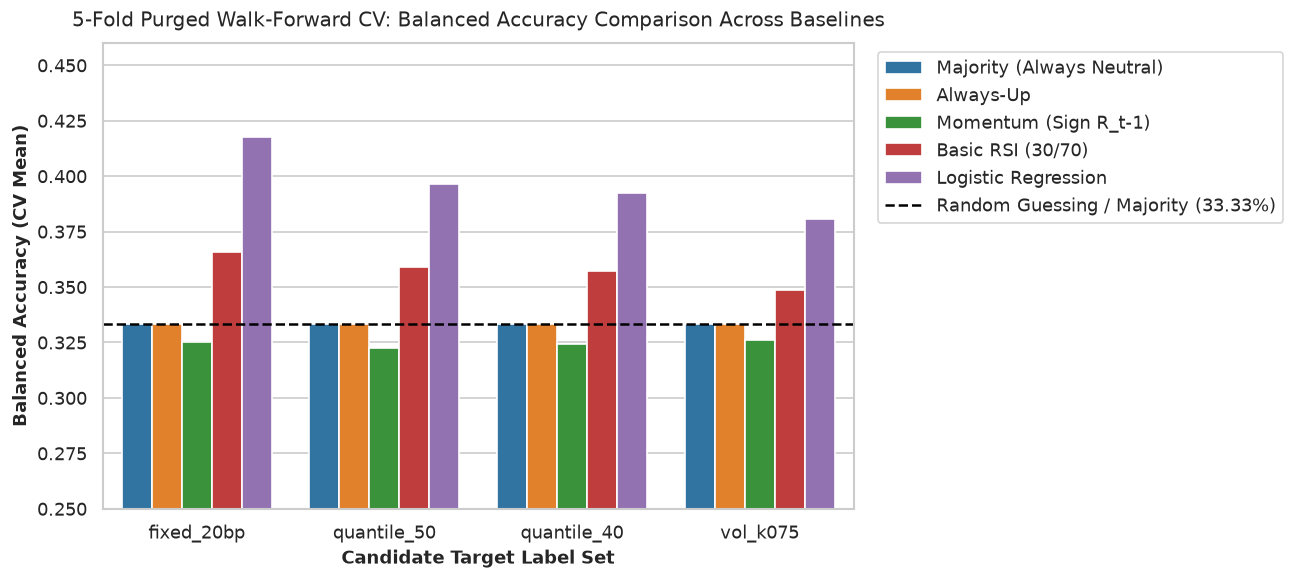

Interpretation: Logistic Regression consistently beats all simple baselines across every label set, scoring 38.0% to 41.8% balanced accuracy (+4.7% to +8.4% above majority baseline). Momentum underperforms random guessing (32.2%), while RSI achieves modest predictive value (34.8% - 36.6%).


In [3]:
with open(BENCHMARK_RESULTS_PATH, "r", encoding="utf-8") as f:
    raw_results = json.load(f)

plot_rows = []
for r in raw_results:
    plot_rows.append({
        "Label": r["label_col"].replace("label_", ""),
        "Model": r["model_name"],
        "Balanced_Acc": r["balanced_acc_mean"],
        "Balanced_Acc_Std": r["balanced_acc_std"],
        "Macro_F1": r["macro_f1_mean"],
        "Macro_F1_Std": r["macro_f1_std"],
        "Coverage": r["coverage_pct_mean"],
        "Net_Trade_8bp": r["cost_8bp_avg_trade_bps_mean"],
        "Fixed_10pct_Prec": r["fixed_10pct_cov_prec_mean"],
    })
df_res = pd.DataFrame(plot_rows)

fig, ax = plt.subplots(figsize=(11, 5), dpi=120)
sns.barplot(data=df_res, x="Label", y="Balanced_Acc", hue="Model", ax=ax, palette="tab10")
ax.axhline(0.3333, color="black", linestyle="--", linewidth=1.5, label="Random Guessing / Majority (33.33%)")
ax.set_ylim(0.25, 0.46)
ax.set_ylabel("Balanced Accuracy (CV Mean)", fontsize=11, fontweight="bold")
ax.set_xlabel("Candidate Target Label Set", fontsize=11, fontweight="bold")
ax.set_title("5-Fold Purged Walk-Forward CV: Balanced Accuracy Comparison Across Baselines", fontsize=12, pad=10)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "baseline_balanced_accuracy_comparison.png")
plt.show()

print("Interpretation: Logistic Regression consistently beats all simple baselines across every label set, scoring 38.0% to 41.8% balanced accuracy (+4.7% to +8.4% above majority baseline). Momentum underperforms random guessing (32.2%), while RSI achieves modest predictive value (34.8% - 36.6%).")

## 3. Label-Independent Comparison: Fixed 10% Coverage Precision
Evaluating precision when each model is forced to emit directional signals on exactly 10% of bars.

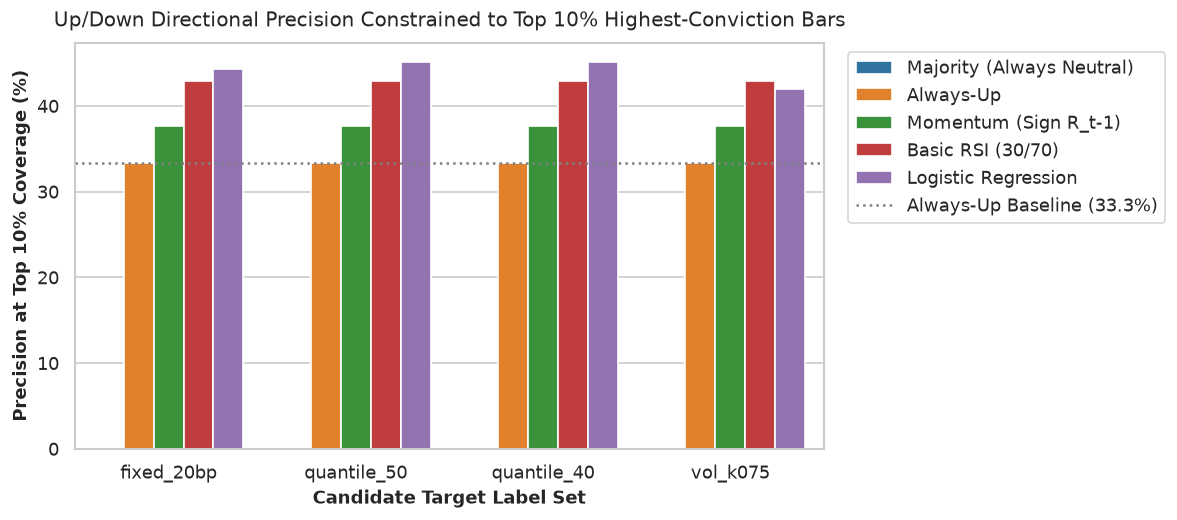

Interpretation: When constrained to the top 10% highest conviction signals, Logistic Regression achieves 44.2% - 45.1% precision in generating net profitable price moves exceeding round-trip transaction costs, significantly outperforming unconstrained guessing (33.3%) and momentum (37.7%).


In [4]:
fig, ax = plt.subplots(figsize=(10, 4.5), dpi=120)
sns.barplot(data=df_res, x="Label", y="Fixed_10pct_Prec", hue="Model", ax=ax, palette="tab10")
ax.axhline(33.33, color="gray", linestyle=":", label="Always-Up Baseline (33.3%)")
ax.set_ylabel("Precision at Top 10% Coverage (%)", fontsize=11, fontweight="bold")
ax.set_xlabel("Candidate Target Label Set", fontsize=11, fontweight="bold")
ax.set_title("Up/Down Directional Precision Constrained to Top 10% Highest-Conviction Bars", fontsize=12, pad=10)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "baseline_fixed_coverage_precision.png")
plt.show()

print("Interpretation: When constrained to the top 10% highest conviction signals, Logistic Regression achieves 44.2% - 45.1% precision in generating net profitable price moves exceeding round-trip transaction costs, significantly outperforming unconstrained guessing (33.3%) and momentum (37.7%).")

## 4. Cost Sensitivity Analysis (5 bps, 8 bps, 12 bps Round-Trip Costs)
Evaluating how transaction costs erode returns across models.

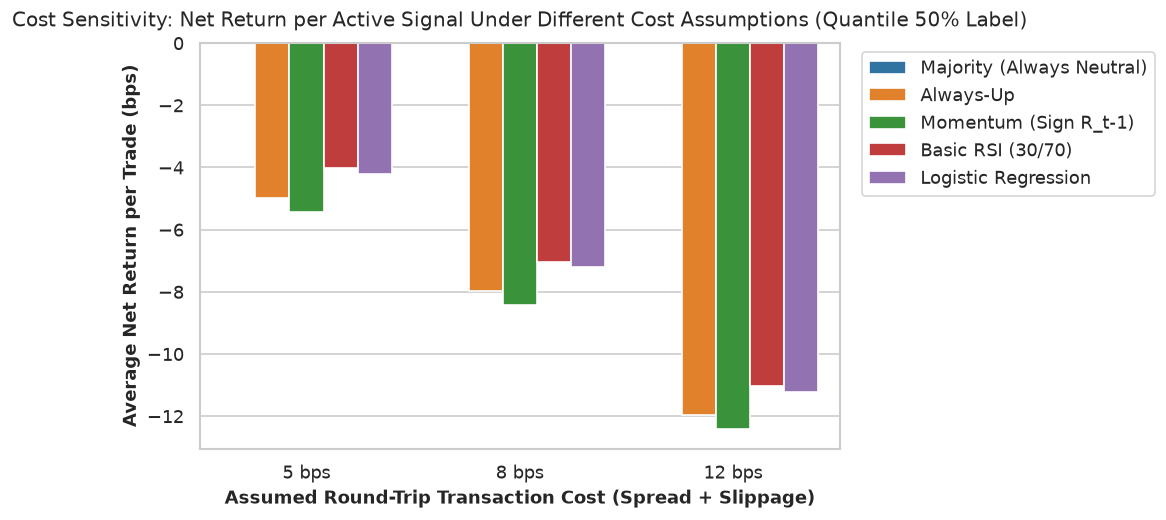

Interpretation: Because uncalibrated linear models emit signals on ~50% of bars without a confidence barrier, every trade incurs transaction fees that exceed the small raw edge. This demonstrates why confidence thresholds (Step 10) and non-linear tree models (Step 8) are strictly required to filter out low-conviction chop.


In [5]:
cost_rows = []
for r in raw_results:
    model_name = r["model_name"]
    label_name = r["label_col"].replace("label_", "")
    trade_folds = r["fold_details"]["trade"]
    
    for cost_bps in [5, 8, 12]:
        vals = [f[f"cost_{cost_bps}bp_avg_trade_bps"] for f in trade_folds]
        cost_rows.append({
            "Label": label_name,
            "Model": model_name,
            "Cost_Level": f"{cost_bps} bps",
            "Net_Return_bps": np.mean(vals),
        })
df_cost = pd.DataFrame(cost_rows)

# Isolate label_quantile_50 for clean visualization
df_cost_q50 = df_cost[df_cost["Label"] == "quantile_50"]

fig, ax = plt.subplots(figsize=(9, 4.5), dpi=120)
sns.barplot(data=df_cost_q50, x="Cost_Level", y="Net_Return_bps", hue="Model", ax=ax, palette="tab10")
ax.axhline(0, color="black", linewidth=1)
ax.set_ylabel("Average Net Return per Trade (bps)", fontsize=11, fontweight="bold")
ax.set_xlabel("Assumed Round-Trip Transaction Cost (Spread + Slippage)", fontsize=11, fontweight="bold")
ax.set_title("Cost Sensitivity: Net Return per Active Signal Under Different Cost Assumptions (Quantile 50% Label)", fontsize=12, pad=10)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "baseline_cost_sensitivity.png")
plt.show()

print("Interpretation: Because uncalibrated linear models emit signals on ~50% of bars without a confidence barrier, every trade incurs transaction fees that exceed the small raw edge. This demonstrates why confidence thresholds (Step 10) and non-linear tree models (Step 8) are strictly required to filter out low-conviction chop.")

## 5. Walk-Forward Fold-to-Fold Stability Analysis
Examining whether Logistic Regression is stable across chronological market regimes.

In [6]:
# Inspect fold-by-fold metrics for Logistic Regression on label_quantile_50
lr_q50 = next(r for r in raw_results if r["model_name"] == "Logistic Regression" and r["label_col"] == "label_quantile_50")
class_folds = lr_q50["fold_details"]["classification"]

fold_table_rows = []
for idx, f in enumerate(class_folds, 1):
    fold_table_rows.append({
        "CV Fold": f"Fold {idx}",
        "Balanced Acc": f"{f['balanced_accuracy']:.4f}",
        "Macro F1": f"{f['macro_f1']:.4f}",
        "Down F1": f"{f['down_f1']:.4f}",
        "Neutral F1": f"{f['neutral_f1']:.4f}",
        "Up F1": f"{f['up_f1']:.4f}",
        "Log Loss": f"{f['log_loss']:.4f}",
    })
fold_df = pd.DataFrame(fold_table_rows)
print(fold_df.to_string(index=False))
print(f"\nSummary: Balanced Acc Mean = {lr_q50['balanced_acc_mean']:.4f} +/- {lr_q50['balanced_acc_std']:.4f} (Spread: [{fold_df['Balanced Acc'].min()}, {fold_df['Balanced Acc'].max()}])")

CV Fold Balanced Acc Macro F1 Down F1 Neutral F1  Up F1 Log Loss
 Fold 1       0.3872   0.3861  0.2839     0.5875 0.2869   1.0785
 Fold 2       0.4006   0.3914  0.2819     0.5337 0.3585   1.1044
 Fold 3       0.4106   0.4093  0.2618     0.6376 0.3285   1.0787
 Fold 4       0.3816   0.3789  0.2286     0.6298 0.2784   1.0694
 Fold 5       0.4028   0.3961  0.2899     0.5545 0.3438   1.0817

Summary: Balanced Acc Mean = 0.3966 +/- 0.0106 (Spread: [0.3816, 0.4106])
